In [4]:
### Follow this notebook for results relating to different harmonic oscialltor frequency in different regions 

In [5]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
from Minimal_Model_2D import *
import time

np.set_printoptions(threshold=sys.maxsize)

In [11]:
class Minimal_Model_diff_omega(twoD_Minimal_Model):

    ### overriding a H same spin method to include array of omega 

    def __init__(self, n, nsm, nsc, m, ax, ay, omega, alphat=0, delta=0, meff_sc=1, meff_sm = 1 , mu_sc = 0, mu_sm=0, dis_mean=0, dis_var=1, px=False, py=False,  epsilon=0):

        """
        Initializes a new instance of the oneD_Minimal_Model class.
        
        Args:
            n (int): The number of horizontal lattice points of the system.
            nsm (int): The number of horizontal lattice points of the semiconductor weak link.
            nsc (int): The number of horizontal lattice points of the superconductor on both sides.
            m (int): The number of vertical lattive points
            ax (float): The horizontal (x) lattice spacing.
            ay (float): The vertical (y) lattice spacing.
            meff (float): Effective mass 
            alphat (float): spin orbit coupling constant
            omega (array float): omega is a nX1 array giving omega values dependent on x  
            mu_s (float): chemical potential of the superconducting region of SNS
            mu_sm (float): chemical potential of the semiconductingconducting region of SNS
            px (bool, optional): Flag indicating periodicity in x direction. Defaults to False.
            epsilon (float): Kx^4 prefactor to remove higher k states from dipping

        Notes:
            - The ordering of lattice points for kx, kxsq, kxcu(imported for operator class file) is from left to right, bottom to top, similar to x and y axis in 2D g

        """

        #print("passed through new init")

        self.n = n
        self.nsm = nsm
        self.nsc = nsc
        self.m = m
        self.ax = ax
        self.ay = ay
        self.omega = omega
        self.meff_sc = meff_sc
        self.meff_sm = meff_sm
        self.alphat = alphat
        self.delta = delta
        self.mu_sc = mu_sc
        self.mu_sm  = mu_sm
        self.dis_mean = dis_mean
        self.dis_var = dis_var
        self.px = px
        self.py = py
        self.epsilon = epsilon
        self.twodOP = Op.Operators_2d(self.n, self.m, self.ax, self.ay, self.px, self.py)
        self.onedOP =  Op.Operators_2d(1, self.m, 1, self.ay, self.px, self.py)

    def SHO_pot_diff_omega(self):

        #print('passed through SHO_pot_diff_omega')

        row = np.empty(0)
        col = np.empty(0)
        data = np.empty(0)

        shift = (((self.m//2))*self.ay)

        for j in range(self.m):

            for i in range(self.n):

                y_sq_at_that_lattice_point = ((j)*self.ay-shift)**2

                sho_pot_at_that_point = 1/4/hbm * self.meff_sm * self.omega[i]**2 * y_sq_at_that_lattice_point
            
                row = np.append(row, j*self.n + i)
                col = np.append(col, j*self.n + i)
                data = np.append(data, sho_pot_at_that_point)

        M = csr_matrix((data,(row,col)),shape=(self.m*self.n, self.m*self.n))

        return M

    def H_same_spin(self, x_ct= 0, y_ct=0, z_ct=50, z_im=50.2, z_qw=0, f_ct=0, dis_mag=0, uncorr_var=1, lmbda=0, seed=None, kx=0, ky=0):

        #print('H same spin overided')

        M = hbm/self.meff_sm* self.twodOP.KxSq(kx) + hbm/self.meff_sm* self.twodOP.KySq(ky) - self.chem_pot() + self.SHO_pot_diff_omega()

        return M

In [12]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized Ge
MEFF_SM = 0.023     # Ge
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 20        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 8           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 100           # Width in nm
OMEGA_const = 2*4*hbm/LY**2/MEFF_SC

OMEGA = np.ones(NTOT)*OMEGA_const

print('lengths=', M*AY, LY)

#print('subband energies=', OMEGA/2, 3*OMEGA/2)

print('4t=', 4*hbm/AX**2/MEFF_SM)

MU_SC =   OMEGA_const/2 +OMEGA_const/10  # in between two subbands - such that we get two abs prferably 
MU_SM =   OMEGA_const/2 +OMEGA_const/10  # in between two subbands - such that we get two abs prferably

#print('mu = ', MU_SM)


UNCORR_VAR = 0  ### uncorrelated variance of disorder
LMBDA = 0
SEED = 58  ## seed for the disorder

ModCT = Minimal_Model_diff_omega(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

lengths= 300 100
4t= 265.2688053453919


In [13]:
### testing the child class above , should same result as the one in minimal 2d model whithout charge trap or disorder

In [13]:
H = ModCT.H_sys(PHI, 'li')

E = eigsh(H, k=K_NUM, sigma=0, return_eigenvectors=False )

Es = np.sort(E)/DELTA

#Ep[i,:] = Es

print(Es)

#print(H.shape)

H same spin overided
passed through SHO_pot_diff_omega
H same spin overided
passed through SHO_pot_diff_omega
H same spin overided
passed through SHO_pot_diff_omega
H same spin overided
passed through SHO_pot_diff_omega
[-0.5589641  -0.55839192 -0.11331183 -0.1129324   0.1129324   0.11331183
  0.55839192  0.5589641 ]


In [19]:
0.11331183 - 0.1129324

0.00037943000000000005

In [14]:
### NOW that it gives same result as correct, lets check for the case where the omega in the middle region is different
### still making sure that the middle omega and mu is still in first subabnd region 
### look at spin splitting vs varying omega in middle region later 

In [15]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized Ge
MEFF_SM = 0.023     # Ge
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 20        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 8           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 100           # Width in nm
OMEGA_const = 2*4*hbm/LY**2/MEFF_SC


LY2 = 95 
OMEGA_sm = 2*4*hbm/LY2**2/MEFF_SM

OMEGA = np.concatenate((np.ones(NSC)*OMEGA_const, np.ones(NSM)*OMEGA_sm, np.ones(NSC)*OMEGA_const))

print('lengths=', M*AY, LY)

print('subband energies sc=', OMEGA_const/2, 3*OMEGA_const/2)

print('subband energies sm=', OMEGA_sm/2, 3*OMEGA_sm/2)

print('4t=', 4*hbm/AX**2/MEFF_SM)

MU_SC =   OMEGA_const/2 +OMEGA_const/10  # in between two subbands - such that we get two abs prferably 
MU_SM =   OMEGA_const/2 +OMEGA_const/10  # in between two subbands - such that we get two abs prferably

print('mu = ', MU_SM)


UNCORR_VAR = 0  ### uncorrelated variance of disorder
LMBDA = 0
SEED = 58  ## seed for the disorder

ModCT = Minimal_Model_diff_omega(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

lengths= 300 100
subband energies sc= 0.30505912614720065 0.915177378441602
subband energies sm= 0.33801565224066554 1.0140469567219967
4t= 122.02365045888027
mu =  0.3660709513766408
passed through new init


In [16]:
H = ModCT.H_sys(PHI, 'li')

E = eigsh(H, k=K_NUM, sigma=0, return_eigenvectors=False )

Es = np.sort(E)/DELTA

#Ep[i,:] = Es

print(Es)

#print(H.shape)

H same spin overided
passed through SHO_pot_diff_omega
H same spin overided
passed through SHO_pot_diff_omega
H same spin overided
passed through SHO_pot_diff_omega
H same spin overided
passed through SHO_pot_diff_omega
[-0.64302166 -0.64274069 -0.12311756 -0.12295124  0.12295124  0.12311756
  0.64274069  0.64302166]


In [20]:
0.12311756 - 0.12295124

0.00016631999999999758

In [18]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized Ge
MEFF_SM = 0.023     # Ge
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 20        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 8           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 100           # Width in nm
OMEGA_const = 2*4*hbm/LY**2/MEFF_SC


LY2 = 95 
OMEGA_sm = 2*4*hbm/LY2**2/MEFF_SM

OMEGA = np.concatenate((np.ones(NSC)*OMEGA_const, np.ones(NSM)*OMEGA_sm, np.ones(NSC)*OMEGA_const))

print('lengths=', M*AY, LY)

print('subband energies sc=', OMEGA_const/2, 3*OMEGA_const/2)

print('subband energies sm=', OMEGA_sm/2, 3*OMEGA_sm/2)

print('4t=', 4*hbm/AX**2/MEFF_SM)

MU_SC =   OMEGA_const/2 +OMEGA_const/10  # in between two subbands - such that we get two abs prferably 
MU_SM =   OMEGA_sm/2 +OMEGA_sm/10  # in between two subbands - such that we get two abs prferably

print('mu = ', MU_SM)


UNCORR_VAR = 0  ### uncorrelated variance of disorder
LMBDA = 0
SEED = 58  ## seed for the disorder

ModCT = Minimal_Model_diff_omega(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

H = ModCT.H_sys(PHI, 'li')

E = eigsh(H, k=K_NUM, sigma=0, return_eigenvectors=False )

Es = np.sort(E)/DELTA

#Ep[i,:] = Es

print(Es)

#print(H.shape)


lengths= 300 100
subband energies sc= 0.30505912614720065 0.915177378441602
subband energies sm= 0.33801565224066554 1.0140469567219967
4t= 122.02365045888027
mu =  0.40561878268879864
passed through new init
H same spin overided
passed through SHO_pot_diff_omega
H same spin overided
passed through SHO_pot_diff_omega
H same spin overided
passed through SHO_pot_diff_omega
H same spin overided
passed through SHO_pot_diff_omega
[-0.54329929 -0.54262627 -0.13482591 -0.13436756  0.13436756  0.13482591
  0.54262627  0.54329929]


In [22]:
0.13482591 - 0.13436756

0.00045834999999999626

In [14]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized Ge
MEFF_SM = 0.023     # Ge
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 20        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 8           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 100           # Width in nm
OMEGA_const = 2*4*hbm/LY**2/MEFF_SC


LY2 = 87 
OMEGA_sm = 2*4*hbm/LY2**2/MEFF_SM

OMEGA_sm_array = np.linspace(OMEGA_const, OMEGA_sm, 21)


print('lengths=', M*AY, LY)

print('subband energies sc=', OMEGA_const/2, 3*OMEGA_const/2)

print('subband energies sm=', OMEGA_sm/2, 3*OMEGA_sm/2)

print('4t=', 4*hbm/AX**2/MEFF_SM)

MU_SC =   OMEGA_const/2 +OMEGA_const/20  # in between two subbands - such that we get two abs prferably 
#MU_SM =   OMEGA_sm/2 +OMEGA_sm/10  # in between two subbands - such that we get two abs prferably
MU_SM = OMEGA_sm_array/2 + OMEGA_const/20

print('mu_sm = ', MU_SM )

print('mu_sc = ', MU_SC)

UNCORR_VAR = 0  ### uncorrelated variance of disorder
LMBDA = 0
SEED = 58  ## seed for the disorder

Ep = np.empty((OMEGA_sm_array.shape[0], K_NUM))

for i in range(OMEGA_sm_array.shape[0]):

    OMEGA = np.concatenate((np.ones(NSC)*OMEGA_const, np.ones(NSM)*OMEGA_sm_array[i], np.ones(NSC)*OMEGA_const))

    ModCT = Minimal_Model_diff_omega(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM[i])

    H = ModCT.H_sys(PHI, 'li')

    E = eigsh(H, k=K_NUM, sigma=0, return_eigenvectors=False )

    Es = np.sort(E)/DELTA

    Ep[i,:] = Es

    #Ep[i,:] = Es

    print(Es)

    #print(H.shape)


np.save("linear_E_vs_omega_sm_mu_const_wrt_first_sm_subband.npy", Ep)



lengths= 300 100
subband energies sc= 0.6631720133634798 1.9895160400904393
subband energies sm= 0.8761686000310209 2.6285058000930626
4t= 265.2688053453919
mu_sm =  [0.72948921 0.74013904 0.75078887 0.7614387  0.77208853 0.78273836
 0.79338819 0.80403802 0.81468785 0.82533768 0.83598751 0.84663734
 0.85728717 0.867937   0.87858683 0.88923665 0.89988648 0.91053631
 0.92118614 0.93183597 0.9424858 ]
mu_sc =  0.7294892146998277
[-0.81154687 -0.80923422 -0.32619578 -0.32477326  0.32477326  0.32619578
  0.80923422  0.81154687]
[-0.81177015 -0.80953062 -0.3263964  -0.32501893  0.32501893  0.3263964
  0.80953062  0.81177015]
[-0.81198092 -0.8098117  -0.32659627 -0.32526213  0.32526213  0.32659627
  0.8098117   0.81198092]
[-0.81217985 -0.81007824 -0.32679608 -0.32550362  0.32550362  0.32679608
  0.81007824  0.81217985]
[-0.81236756 -0.81033094 -0.32699645 -0.32574407  0.32574407  0.32699645
  0.81033094  0.81236756]
[-0.81254462 -0.81057051 -0.32719791 -0.32598407  0.32598407  0.32719791
  0

Text(0, 0.5, 'spin splitting(meV)')

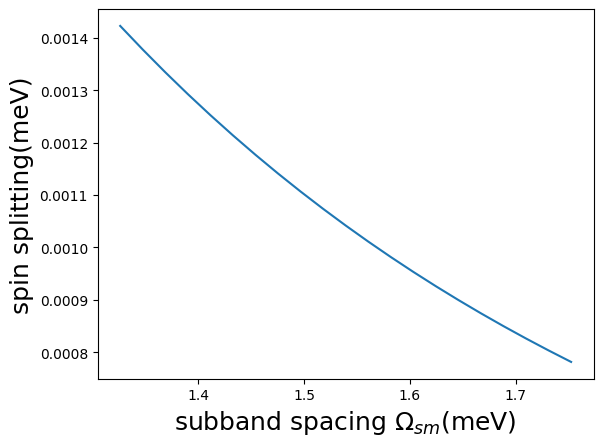

In [15]:
plt.plot(OMEGA_sm_array, Ep[:,K_NUM//2+1]-Ep[:, K_NUM//2])
plt.xlabel(r"subband spacing $\Omega_{sm}$(meV)", fontsize=18)
plt.ylabel("spin splitting(meV)", fontsize=18)

In [14]:
print(OMEGA_sm_array)

[1.32634403 1.34764369 1.36894334 1.390243   1.41154266 1.43284232
 1.45414198 1.47544164 1.4967413  1.51804095 1.53934061 1.56064027
 1.58193993 1.60323959 1.62453925 1.64583891 1.66713857 1.68843822
 1.70973788 1.73103754 1.7523372 ]


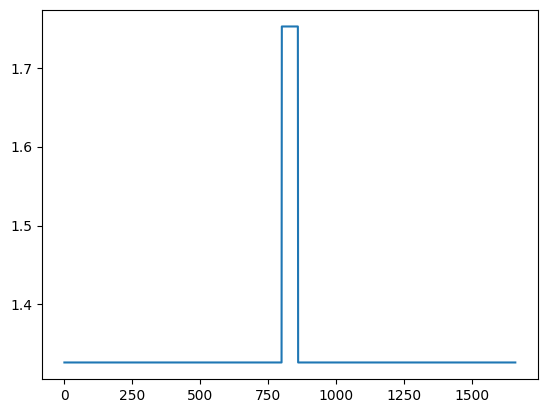

In [15]:
plt.plot(OMEGA)

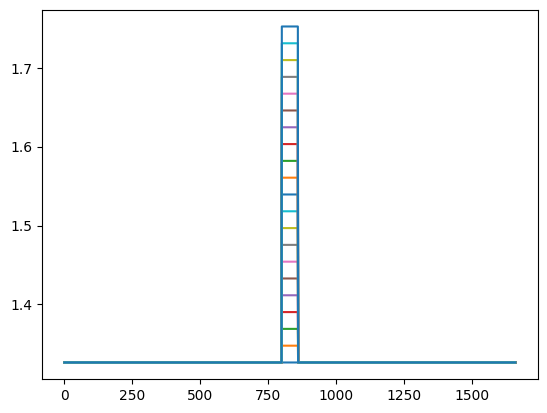

In [16]:

for i in range(OMEGA_sm_array.shape[0]):

    OMEGA = np.concatenate((np.ones(NSC)*OMEGA_const, np.ones(NSM)*OMEGA_sm_array[i], np.ones(NSC)*OMEGA_const))

    plt.plot(OMEGA)
